# School Resource Analysis

How are expenditure per student and reading scores associated?

Data: [AER/CASchools](https://vincentarelbundock.github.io/Rdatasets/doc/AER/CASchools.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: District-level observational data; income and learner composition may confound results.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'School Resource Analysis',
 'executed_utc': '2026-11-21T10:14:14.787474+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/AER/CASchools.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/AER/CASchools.html',
 'sha256': '895568b58b16b78e03b344502b6ff76b27f7d22dcbe3a699e766a54dd151fee8',
 'raw_rows': 420,
 'analysis_rows': 420,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8',
 'pearson': 0.21792681805878902,
 'spearman': 0.13218789822443724}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,420
1,district,int64,0,0.0,420
2,school,object,0,0.0,409
3,county,object,0,0.0,45
4,grades,object,0,0.0,2
5,students,int64,0,0.0,391
6,teachers,float64,0,0.0,374
7,calworks,float64,0,0.0,411
8,lunch,float64,0,0.0,407
9,computer,int64,0,0.0,270


## SQL and analysis
Complete-pair scatter plot of expenditure and read, with Pearson and Spearman correlations. No regression adjustment or causal claim.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "expenditure" AS predictor, "read" AS outcome FROM observations ORDER BY "expenditure";

Among 420 complete observations, Pearson r = 0.218 and Spearman rho = 0.132.


,predictor,outcome
0,3926.069580,659.799988
1,4016.416260,667.599976
2,4023.531738,658.500000
3,4079.129150,636.099976
4,4136.250977,631.099976
5,4138.305664,651.400024
6,4145.835938,660.299988
7,4219.406250,651.599976
8,4260.306641,653.400024
9,4273.993164,679.000000


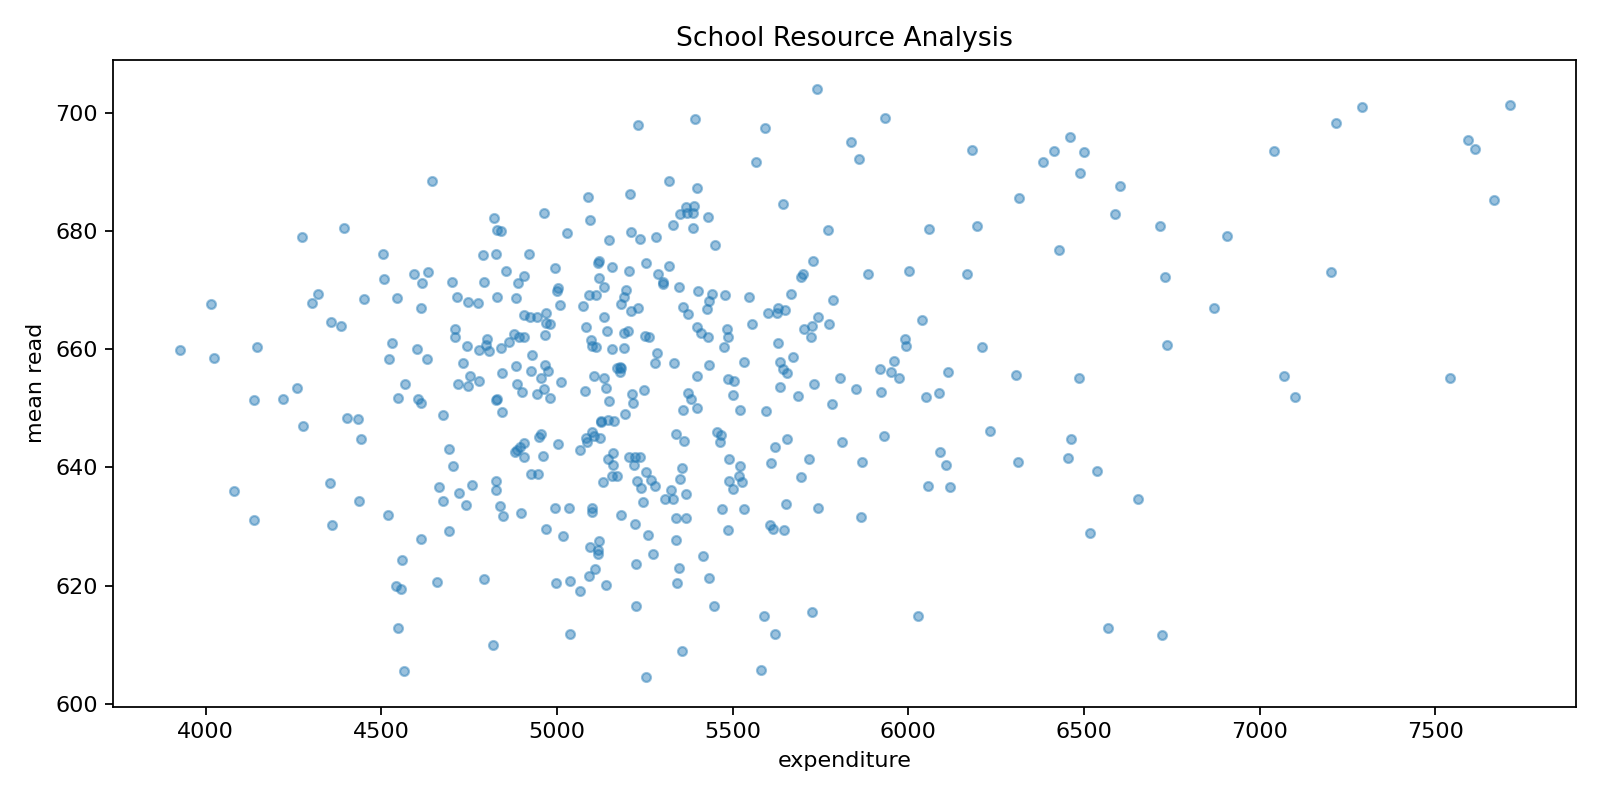

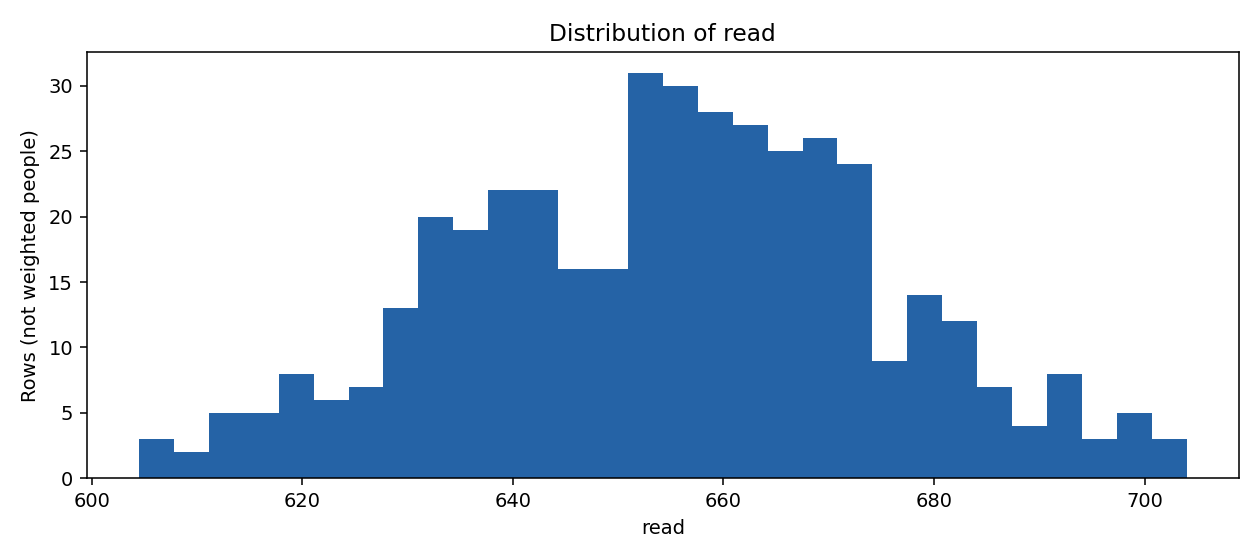

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
District-level observational data; income and learner composition may confound results.

**Next action:** Compare adjusted associations and resource allocation context.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.